<a href="https://colab.research.google.com/github/anagharsa/ppd-detection/blob/main/PPD_Final_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Installs & Imports

In [ ]:
pip install mne

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 43.7 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/dataset

'Final Dataset.zip'


In [ ]:
!unzip -j /content/drive/MyDrive/dataset/'Final Dataset.zip' -d /content/drive/MyDrive/dataset

Archive:  /content/drive/MyDrive/dataset/Final Dataset.zip
  inflating: /content/drive/MyDrive/dataset/1 S1.edf  
  inflating: /content/drive/MyDrive/dataset/1 S10.edf  
  inflating: /content/drive/MyDrive/dataset/1 S11.edf  
  inflating: /content/drive/MyDrive/dataset/1 S12.edf  
  inflating: /content/drive/MyDrive/dataset/1 S13.edf  
  inflating: /content/drive/MyDrive/dataset/1 S14.edf  
  inflating: /content/drive/MyDrive/dataset/1 S2.edf  
  inflating: /content/drive/MyDrive/dataset/1 S3.edf  
  inflating: /content/drive/MyDrive/dataset/1 S4.edf  
  inflating: /content/drive/MyDrive/dataset/1 S5.edf  
  inflating: /content/drive/MyDrive/dataset/1 S6.edf  
  inflating: /content/drive/MyDrive/dataset/1 S7.edf  
  inflating: /content/drive/MyDrive/dataset/1 S8.edf  
  inflating: /content/drive/MyDrive/dataset/1 S9.edf  
  inflating: /content/drive/MyDrive/dataset/2 S1.edf  
  inflating: /content/drive/MyDrive/dataset/2 S2.edf  
  inflating: /content/drive/MyDrive/dataset/2 S3.edf  
 

In [ ]:
!ls /content/drive/MyDrive/dataset

'1 S10.edf'  '1 S4.edf'  '2 S3.edf'   '3 S11.edf'  '3 S6.edf'
'1 S11.edf'  '1 S5.edf'  '2 S4.edf'   '3 S12.edf'  '3 S7.edf'
'1 S12.edf'  '1 S6.edf'  '2 S5.edf'   '3 S13.edf'  '3 S8.edf'
'1 S13.edf'  '1 S7.edf'  '2 S6.edf'   '3 S1.edf'   '3 S9.edf'
'1 S14.edf'  '1 S8.edf'  '2 S7.edf'   '3 S2.edf'   'Final Dataset.zip'
'1 S1.edf'   '1 S9.edf'  '2 S8.edf'   '3 S3.edf'
'1 S2.edf'   '2 S1.edf'  '2 S9.edf'   '3 S4.edf'
'1 S3.edf'   '2 S2.edf'  '3 S10.edf'  '3 S5.edf'


In [ ]:
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
import glob
import os.path
from sklearn.decomposition import FastICA
from scipy.integrate import simps
from scipy import signal
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import BatchNormalization
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, Input
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import Model
from keras.applications import VGG16, InceptionV3, VGG19, Xception

# PREPROCESSING

In [ ]:
path = '/content/drive/MyDrive/dataset/*'
file_name = glob.glob(path)
list_files = [file for file in file_name]


for i in list_files:
  if i.endswith('.edf'):
    edf = mne.io.read_raw_edf(i, preload=True,
                              include=['EEG Fp1-LE', 'EEG Fp2-LE', 'EEG F3-LE', 'EEG F4-LE', 'EEG F7-LE',
                                                        'EEG Fz-LE', 'EEG F8-LE'])
    mne.rename_channels(edf.info, {'EEG Fp1-LE':'Fp1', 'EEG Fp2-LE':'Fp2', 'EEG F3-LE':'F3', 'EEG F4-LE':'F4',
                                   'EEG F7-LE':'F7', 'EEG Fz-LE':'Fz', 'EEG F8-LE':'F8'})
    print('\n RAW EDF\n')
    edf.plot()
    montage = mne.channels.make_standard_montage('standard_1020')
    edf.set_montage(montage)
    spectrum = edf.compute_psd()
    print('\n PSD & Topo Plots\n')
    spectrum.plot(average=True, picks="data", exclude="bads")
    spectrum.plot_topomap()
    bandpass_edf = edf.copy().filter(l_freq=0.1,h_freq=70)
    notch_edf = bandpass_edf.copy().notch_filter(freqs=50)
    print('\n FILTERED EDF\n')
    notch_edf.plot()
    header = ','.join(notch_edf.ch_names)
    name_of_file = str(i[:-4]) +'.csv'
    np.savetxt(name_of_file, notch_edf.get_data().T, delimiter=',', header=header)


In [ ]:
!ls /content/drive/MyDrive/dataset

'1 S10.csv'  '1 S3.edf'  '2 S2.csv'  '2 S9.edf'   '3 S4.csv'
'1 S10.edf'  '1 S4.csv'  '2 S2.edf'  '3 S10.csv'  '3 S4.edf'
'1 S11.csv'  '1 S4.edf'  '2 S3.csv'  '3 S10.edf'  '3 S5.csv'
'1 S11.edf'  '1 S5.csv'  '2 S3.edf'  '3 S11.csv'  '3 S5.edf'
'1 S12.csv'  '1 S5.edf'  '2 S4.csv'  '3 S11.edf'  '3 S6.csv'
'1 S12.edf'  '1 S6.csv'  '2 S4.edf'  '3 S12.csv'  '3 S6.edf'
'1 S13.csv'  '1 S6.edf'  '2 S5.csv'  '3 S12.edf'  '3 S7.csv'
'1 S13.edf'  '1 S7.csv'  '2 S5.edf'  '3 S13.csv'  '3 S7.edf'
'1 S14.csv'  '1 S7.edf'  '2 S6.csv'  '3 S13.edf'  '3 S8.csv'
'1 S14.edf'  '1 S8.csv'  '2 S6.edf'  '3 S1.csv'   '3 S8.edf'
'1 S1.csv'   '1 S8.edf'  '2 S7.csv'  '3 S1.edf'   '3 S9.csv'
'1 S1.edf'   '1 S9.csv'  '2 S7.edf'  '3 S2.csv'   '3 S9.edf'
'1 S2.csv'   '1 S9.edf'  '2 S8.csv'  '3 S2.edf'   'Final Dataset.zip'
'1 S2.edf'   '2 S1.csv'  '2 S8.edf'  '3 S3.csv'
'1 S3.csv'   '2 S1.edf'  '2 S9.csv'  '3 S3.edf'


In [ ]:
mkdir /content/drive/MyDrive/dataset/ICA

In [ ]:
for files in glob.glob("/content/drive/MyDrive/dataset/*.csv"):
  X = pd.read_csv(files)
  scaler = MinMaxScaler()
  X = scaler.fit_transform(X)

  # Compute ICA
  ica = FastICA(whiten='unit-variance')
  ICA = ica.fit_transform(X)  # Reconstruct signals

  data_frame = pd.DataFrame(ICA)

  data_frame.to_csv('/content/drive/MyDrive/dataset/ICA/'+str(files[31:-4])+'_ica.csv',
                    index=False, header=['Fp1','F3','F7','Fz','Fp2','F4','F8'])

/usr/local/lib/python3.10/dist-packages/sklearn/decomposition/_fastica.py:123: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


In [ ]:
a = pd.read_csv('/content/drive/MyDrive/dataset/ICA/1 S1_ica.csv')
print(a.shape)

(77312, 7)


In [ ]:
ls /content/drive/MyDrive/dataset

'1 S10.csv'  '1 S3.edf'  '2 S2.csv'  '2 S9.edf'   '3 S4.csv'
'1 S10.edf'  '1 S4.csv'  '2 S2.edf'  '3 S10.csv'  '3 S4.edf'
'1 S11.csv'  '1 S4.edf'  '2 S3.csv'  '3 S10.edf'  '3 S5.csv'
'1 S11.edf'  '1 S5.csv'  '2 S3.edf'  '3 S11.csv'  '3 S5.edf'
'1 S12.csv'  '1 S5.edf'  '2 S4.csv'  '3 S11.edf'  '3 S6.csv'
'1 S12.edf'  '1 S6.csv'  '2 S4.edf'  '3 S12.csv'  '3 S6.edf'
'1 S13.csv'  '1 S6.edf'  '2 S5.csv'  '3 S12.edf'  '3 S7.csv'
'1 S13.edf'  '1 S7.csv'  '2 S5.edf'  '3 S13.csv'  '3 S7.edf'
'1 S14.csv'  '1 S7.edf'  '2 S6.csv'  '3 S13.edf'  '3 S8.csv'
'1 S14.edf'  '1 S8.csv'  '2 S6.edf'  '3 S1.csv'   '3 S8.edf'
'1 S1.csv'   '1 S8.edf'  '2 S7.csv'  '3 S1.edf'   '3 S9.csv'
'1 S1.edf'   '1 S9.csv'  '2 S7.edf'  '3 S2.csv'   '3 S9.edf'
'1 S2.csv'   '1 S9.edf'  '2 S8.csv'  '3 S2.edf'   'Final Dataset.zip'
'1 S2.edf'   '2 S1.csv'  '2 S8.edf'  '3 S3.csv'    ICA/
'1 S3.csv'   '2 S1.edf'  '2 S9.csv'  '3 S3.edf'


# FEATURE EXTRACTION

In [ ]:
mkdir /content/drive/MyDrive/dataset/Rel_S_alpha

In [ ]:
for files in glob.glob("/content/drive/MyDrive/dataset/ICA/*.csv"):
  # print('File: ',files)
  low, high = 8, 12
  win = (2/low)*256

  final_list = []
  data = pd.read_csv(files)

  if len(data) !=0:
    result = []
    for i in range(7):
      data_1 = data.iloc[:, i]
      freqs, psd = signal.welch(data_1, 256, nperseg=win)
      # Find intersecting values in frequency vector
      alpha = np.logical_and(freqs >= low, freqs <= high)
      # Frequency resolution
      freq_res = freqs[1] - freqs[0]

      # Compute the absolute power by approximating the area under the curve
      alpha_power = simps(psd[alpha], dx=freq_res)
      # print('Absolute alpha power: %.7f uV^2' % alpha_power)

      total_power = simps(psd, dx=freq_res)
      alpha_rel_power = alpha_power / total_power
      # print('Relative alpha power: %.3f' % alpha_rel_power)
      result.append(alpha_rel_power)
    final_list.append(result)
    # print('Final Feature vals: ',final_list)

    data_frame = pd.DataFrame(final_list)
    data_frame.to_csv('/content/drive/MyDrive/dataset/Rel_S_alpha/'+'Rel_pwr_'+str(files[35:-4])+'.csv',
                        index=False, header=['Fp1','F3','F7','Fz','Fp2','F4','F8'])

In [ ]:
mkdir /content/drive/MyDrive/dataset/Rel_S_theta

In [ ]:
for files in glob.glob("/content/drive/MyDrive/dataset/ICA/*.csv"):
  # print('File: ',files)
  low, high = 4, 8
  win = (2/low)*256

  final_list = []
  data = pd.read_csv(files)

  if len(data) !=0:
    result = []
    for i in range(7):
      data_1 = data.iloc[:, i]
      freqs, psd = signal.welch(data_1, 256, nperseg=win)
      # Find intersecting values in frequency vector
      theta = np.logical_and(freqs >= low, freqs <= high)
      # Frequency resolution
      freq_res = freqs[1] - freqs[0]

      # Compute the absolute power by approximating the area under the curve
      theta_power = simps(psd[theta], dx=freq_res)
      # print('Absolute theta power: %.7f uV^2' % theta_power)

      total_power = simps(psd, dx=freq_res)
      theta_rel_power = theta_power / total_power
      # print('Relative theta power: %.3f' % theta_rel_power)
      result.append(theta_rel_power)
    final_list.append(result)
    # print('Final Feature vals: ',final_list)

    data_frame = pd.DataFrame(final_list)
    data_frame.to_csv('/content/drive/MyDrive/dataset/Rel_S_theta/'+'Rel_pwr_'+str(files[35:-4])+'.csv',
                        index=False, header=['Fp1','F3','F7','Fz','Fp2','F4','F8'])

In [ ]:
mkdir /content/drive/MyDrive/dataset/Rel_S_beta

In [ ]:
for files in glob.glob("/content/drive/MyDrive/dataset/ICA/*.csv"):
  # print('File: ',files)
  low, high = 12, 30
  win = (2/low)*256

  final_list = []
  data = pd.read_csv(files)

  if len(data) !=0:
    result = []
    for i in range(7):
      data_1 = data.iloc[:, i]
      freqs, psd = signal.welch(data_1, 256, nperseg=win)
      # Find intersecting values in frequency vector
      beta = np.logical_and(freqs >= low, freqs <= high)
      # Frequency resolution
      freq_res = freqs[1] - freqs[0]

      # Compute the absolute power by approximating the area under the curve
      beta_power = simps(psd[beta], dx=freq_res)
      # print('Absolute beta power: %.7f uV^2' % beta_power)

      total_power = simps(psd, dx=freq_res)
      beta_rel_power = beta_power / total_power
      # print('Relative beta power: %.3f' % beta_rel_power)
      result.append(beta_rel_power)
    final_list.append(result)
    # print('Final Feature vals: ',final_list)

    data_frame = pd.DataFrame(final_list)
    data_frame.to_csv('/content/drive/MyDrive/dataset/Rel_S_beta/'+'Rel_pwr_'+str(files[35:-4])+'.csv',
                        index=False, header=['Fp1','F3','F7','Fz','Fp2','F4','F8'])

In [ ]:
ls /content/drive/MyDrive/dataset

'1 S10.csv'  '1 S4.csv'  '2 S3.csv'   '3 S11.csv'  '3 S6.csv'
'1 S10.edf'  '1 S4.edf'  '2 S3.edf'   '3 S11.edf'  '3 S6.edf'
'1 S11.csv'  '1 S5.csv'  '2 S4.csv'   '3 S12.csv'  '3 S7.csv'
'1 S11.edf'  '1 S5.edf'  '2 S4.edf'   '3 S12.edf'  '3 S7.edf'
'1 S12.csv'  '1 S6.csv'  '2 S5.csv'   '3 S13.csv'  '3 S8.csv'
'1 S12.edf'  '1 S6.edf'  '2 S5.edf'   '3 S13.edf'  '3 S8.edf'
'1 S13.csv'  '1 S7.csv'  '2 S6.csv'   '3 S1.csv'   '3 S9.csv'
'1 S13.edf'  '1 S7.edf'  '2 S6.edf'   '3 S1.edf'   '3 S9.edf'
'1 S14.csv'  '1 S8.csv'  '2 S7.csv'   '3 S2.csv'   'Final Dataset.zip'
'1 S14.edf'  '1 S8.edf'  '2 S7.edf'   '3 S2.edf'    ICA/
'1 S1.csv'   '1 S9.csv'  '2 S8.csv'   '3 S3.csv'    Rel_S_alpha/
'1 S1.edf'   '1 S9.edf'  '2 S8.edf'   '3 S3.edf'    Rel_S_beta/
'1 S2.csv'   '2 S1.csv'  '2 S9.csv'   '3 S4.csv'    Rel_S_theta/
'1 S2.edf'   '2 S1.edf'  '2 S9.edf'   '3 S4.edf'
'1 S3.csv'   '2 S2.csv'  '3 S10.csv'  '3 S5.csv'
'1 S3.edf'   '2 S2.edf'  '3 S10.edf'  '3 S5.edf'


In [ ]:
mkdir /content/drive/MyDrive/dataset/Pics_theta

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_theta/*.csv"):
  # print(str(files[45:46]))
  if files[51:52] == '1':
    data = pd.read_csv(files)
    count+=1

    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      # print(len(data))
      row_list = []
      result = 0
      # k is left
      # n is right
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_theta/'+str(files[51:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)



<ipython-input-22-ff60e8de2bcc>:37: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(64, 64))


In [ ]:
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_theta/*.csv"):
  if files[51:52] == '2':
    data = pd.read_csv(files)
    count+=1
      #column_list = []
      #row_list = []
    #print(len(data))
    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      row_list = []
      result = 0
      # k is left Hemispheric
      # n is right Hemispheric
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_theta/'+str(files[51:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)

In [ ]:
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_theta/*.csv"):
  if files[51:52] == '3':
    data = pd.read_csv(files)
    count+=1
      #column_list = []
      #row_list = []
    #print(len(data))
    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      row_list = []
      result = 0
      # k is left Hemispheric
      # n is right Hemispheric
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_theta/'+str(files[51:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)


In [ ]:
mkdir /content/drive/MyDrive/dataset/Pics_beta

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_beta/*.csv"):
  # print(str(files[45:46]))
  if files[50:51] == '1':
    data = pd.read_csv(files)
    count+=1

    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      # print(len(data))
      row_list = []
      result = 0
      # k is left
      # n is right
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_beta/'+str(files[50:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)

In [ ]:
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_beta/*.csv"):
  if files[50:51] == '2':
    data = pd.read_csv(files)
    count+=1
      #column_list = []
      #row_list = []
    #print(len(data))
    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      row_list = []
      result = 0
      # k is left Hemispheric
      # n is right Hemispheric
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_beta/'+str(files[50:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)

In [ ]:
count = 0
for files in glob.glob("/content/drive/MyDrive/dataset/Rel_S_beta/*.csv"):
  if files[50:51] == '3':
    data = pd.read_csv(files)
    count+=1
      #column_list = []
      #row_list = []
    #print(len(data))
    column_change = ['Fp1','F3','F7','Fz','Fp2','F4','F8']
    data = data[column_change]

    for l in range(len(data)):
      row_list = []
      result = 0
      # k is left Hemispheric
      # n is right Hemispheric
      for k in range(0, 7):
          column_list = []
          result = 0
          for n in range(0, 7):
              result = 0
              a = data.iloc[l, k]
              b = data.iloc[l, n]
              result += (a - b) / (a + b)
              column_list.append(result)
          # print('Column list of',k,'is: ',np.mean(column_list))
          row_list.append(column_list)
      # print('Row list: ',np.mean(row_list))
      image = np.array(row_list)
      # print(image)


      plt.figure(figsize=(64, 64))
      fig, axis = plt.subplots()
      height, width = image.shape
      im = axis.imshow(image, cmap='jet', vmin=-1, vmax=1)


      plt.axis('off'), plt.xticks([]), plt.yticks([])
      """axis.axes.get_xaxis().set_visible(True)
      axis.axes.get_yaxis().set_visible(True)
      plt.tight_layout()"""
      plt.subplots_adjust(left=0, bottom=0, right=1, top=1, hspace=0, wspace=0)
      #fig.colorbar(im, shrink=1.0, aspect=10)
      #plt.show()
      plt.savefig('/content/drive/MyDrive/dataset/Pics_beta/'+str(files[50:-8])+'_pic.png', bbox_inches='tight', pad_inches=0)


In [ ]:
files_t = glob.glob("/content/drive/MyDrive/dataset/Pics_theta/*.png")
print('Theta pics: ',len(files_t))
files_b = glob.glob("/content/drive/MyDrive/dataset/Pics_beta/*.png")
print('Beta pics: ',len(files_b))

Theta pics:  36
Beta pics:  36


In [ ]:
mkdir /content/drive/MyDrive/dataset/Train_theta

mkdir: cannot create directory ‘/content/drive/MyDrive/dataset/Train_theta’: File exists


In [ ]:
import os
os.mkdir("/content/drive/MyDrive/dataset/Train_theta/1")
os.mkdir("/content/drive/MyDrive/dataset/Train_theta/2")
os.mkdir("/content/drive/MyDrive/dataset/Train_theta/3")

In [ ]:
mkdir /content/drive/MyDrive/dataset/Train_beta

In [ ]:
import os
os.mkdir("/content/drive/MyDrive/dataset/Train_beta/1")
os.mkdir("/content/drive/MyDrive/dataset/Train_beta/2")
os.mkdir("/content/drive/MyDrive/dataset/Train_beta/3")

FileExistsError: ignored

In [ ]:
files = glob.glob("/content/drive/MyDrive/dataset/Pics_theta/*")
import re
import shutil
fault_folders = ["1","2","3"]
for file in files:
    pattern = str(file[42:43])
    #for j in range(len(fault_folders)):
    if re.match(pattern, "1"):
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_theta/1")
      shutil.move(file, dest)
    elif re.match(pattern, "2"):
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_theta/2")
      shutil.move(file, dest)
    else:
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_theta/3")
      shutil.move(file, dest)

In [ ]:
files = glob.glob("/content/drive/MyDrive/dataset/Pics_beta/*")
import re
import shutil
fault_folders = ["1","2","3"]
for file in files:
    pattern = str(file[41:42])
    #for j in range(len(fault_folders)):
    if re.match(pattern, "1"):
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_beta/1")
      shutil.move(file, dest)
    elif re.match(pattern, "2"):
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_beta/2")
      shutil.move(file, dest)
    else:
      dest = os.path.join("/content/drive/MyDrive/dataset/Train_beta/3")
      shutil.move(file, dest)

Error: ignored

In [ ]:
files_b1 = glob.glob("/content/drive/MyDrive/dataset/Train_beta/1/*.png")
print('Class 1 files of beta: ',len(files_b1))
files_b2 = glob.glob("/content/drive/MyDrive/dataset/Train_beta/2/*.png")
print('Class 2 files of beta: ',len(files_b2))
files_b3 = glob.glob("/content/drive/MyDrive/dataset/Train_beta/3/*.png")
print('Class 3 files of beta: ',len(files_b3))

Class 1 files of beta:  14
Class 2 files of beta:  9
Class 3 files of beta:  13


In [ ]:
files_t1 = glob.glob("/content/drive/MyDrive/dataset/Train_theta/1/*.png")
print('Class 1 files of theta: ',len(files_t1))
files_t2 = glob.glob("/content/drive/MyDrive/dataset/Train_theta/2/*.png")
print('Class 2 files of theta: ',len(files_t2))
files_t3 = glob.glob("/content/drive/MyDrive/dataset/Train_theta/3/*.png")
print('Class 3 files of theta: ',len(files_t3))

Class 1 files of theta:  14
Class 2 files of theta:  9
Class 3 files of theta:  13


In [ ]:
class_names = ['1', '2', '3']
class_names_label = {class_name:i for i, class_name in enumerate(class_names)}

In [ ]:
from tqdm import tqdm
import cv2
import os
dataset ='/content/drive/MyDrive/dataset/Train_theta/'
t_images = []
t_labels = []
t_output=[]
IMAGE_SIZE = (64, 64)
print("Loading {}".format(dataset))

# Iterate through each folder corresponding to a category
for folder in os.listdir(dataset):
    label = class_names_label[folder]
    #print(folder)
    # Iterate through each image in our folder
    for file in tqdm(os.listdir(os.path.join(dataset, folder))):

        # Get the path name of the image
        img_path = os.path.join(os.path.join(dataset, folder), file)

        # Open and resize the img
        image = cv2.imread(img_path)
        #image = image[6:208,92:420]
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMAGE_SIZE)

        # Append the image and its corresponding label to the output
        t_images.append(image)
        t_labels.append(label)
        #cv2_imshow(image)
        #print(label)
t_images = np.array(t_images, dtype = 'float32')
t_labels = np.array(t_labels, dtype = 'int32')
#print("images=",images)
print("labels=",t_labels[0])

t_output.append((t_images, t_labels))
print(t_images[0].shape)

Loading /content/drive/MyDrive/dataset/Train_theta/


100%|██████████| 13/13 [00:00<00:00, 160.44it/s]

labels= 0
(64, 64, 3)


In [ ]:
from tqdm import tqdm
import cv2
import os
dataset ='/content/drive/MyDrive/dataset/Train_beta/'
b_images = []
b_labels = []
b_output=[]
IMAGE_SIZE = (64, 64)
print("Loading {}".format(dataset))

# Iterate through each folder corresponding to a category
for folder in os.listdir(dataset):
    label = class_names_label[folder]
    #print(folder)
    # Iterate through each image in our folder
    for file in tqdm(os.listdir(os.path.join(dataset, folder))):

        # Get the path name of the image
        img_path = os.path.join(os.path.join(dataset, folder), file)

        # Open and resize the img
        image = cv2.imread(img_path)
        #image = image[6:208,92:420]
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, IMAGE_SIZE)

        # Append the image and its corresponding label to the output
        b_images.append(image)
        b_labels.append(label)
        #cv2_imshow(image)
        #print(label)
b_images = np.array(b_images, dtype = 'float32')
b_labels = np.array(b_labels, dtype = 'int32')
#print("images=",images)
print("labels=",b_labels[0])

b_output.append((b_images, b_labels))
print(b_images[0].shape)

Loading /content/drive/MyDrive/dataset/Train_beta/


100%|██████████| 13/13 [00:00<00:00, 156.12it/s]

labels= 0
(64, 64, 3)


# CNN MODEL

In [ ]:
t_X_train, t_X_test, t_y_train, t_y_test = train_test_split(t_images, t_labels, test_size=0.2, random_state=42)
b_X_train, b_X_test, b_y_train, b_y_test = train_test_split(b_images, b_labels, test_size=0.2, random_state=42)

t_y_train = keras.utils.to_categorical(t_y_train)
t_y_test = keras.utils.to_categorical(t_y_test)

b_y_train = keras.utils.to_categorical(b_y_train)
b_y_test = keras.utils.to_categorical(b_y_test)

In [ ]:
model1 = Sequential()
model1.add(Conv2D(32, (3, 3), input_shape=(64, 64, 3), activation='relu'))
model1.add(MaxPooling2D(pool_size=(2, 2)))
model1.add(Conv2D(64, (3, 3), input_shape=(32, 32, 3), activation='relu'))
model1.add(MaxPooling2D(pool_size=(2, 2)))
model1.add(Conv2D(128, (3, 3), input_shape=(16, 16, 3), activation='relu'))
model1.add(MaxPooling2D(pool_size=(2, 2)))
model1.add(Conv2D(256, (3, 3), input_shape=(8, 8, 3), activation='relu'))
model1.add(MaxPooling2D(pool_size=(2, 2)))
model1.add(Flatten())
model1.add(Dense(512, activation='relu'))
model1.add(Dropout(0.25))
model1.add(Dense(3, activation='softmax'))

In [ ]:
callbacks = EarlyStopping(monitor='val_loss', patience=5, verbose=1, mode='auto')

best_model_file = '/content/drive/MyDrive/dataset/CNN_aug_best_weights.h5'
best_model = ModelCheckpoint(best_model_file, monitor='val_accuracy', verbose = 1, save_best_only = True)

In [ ]:
opt = keras.optimizers.Adam()
model1.compile(loss="categorical_crossentropy", optimizer=opt,
	metrics=["accuracy"])

In [ ]:
history = model1.fit(t_X_train,
                    t_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(t_X_test, t_y_test),
                    callbacks = [best_model],
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 8.0267 - accuracy: 0.3214
Epoch 1: val_accuracy improved from -inf to 0.25000, saving model to /content/drive/MyDrive/dataset/CNN_aug_best_weights.h5
1/1 [==============================] - 2s 2s/step - loss: 8.0267 - accuracy: 0.3214 - val_loss: 89.3137 - val_accuracy: 0.2500
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 87.5140 - accuracy: 0.2500
Epoch 2: val_accuracy did not improve from 0.25000
1/1 [==============================] - 0s 308ms/step - loss: 87.5140 - accuracy: 0.2500 - val_loss: 31.0623 - val_accuracy: 0.2500
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 24.2887 - accuracy: 0.4643
Epoch 3: val_accuracy improved from 0.25000 to 0.50000, saving model to /content/drive/MyDrive/dataset/CNN_aug_best_weights.h5
1/1 [==============================] - 0s 362ms/step - loss: 24.2887 - accuracy: 0.4643 - val_loss: 25.0894 - val_accuracy: 0.5000
Epoch 4/100
1/1 [===========

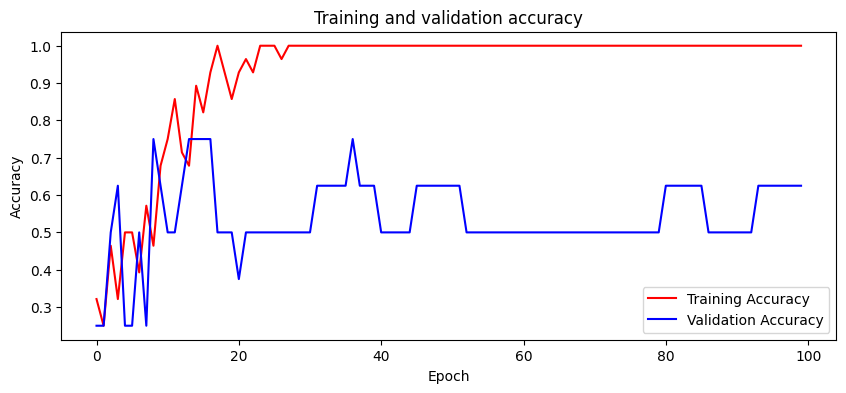

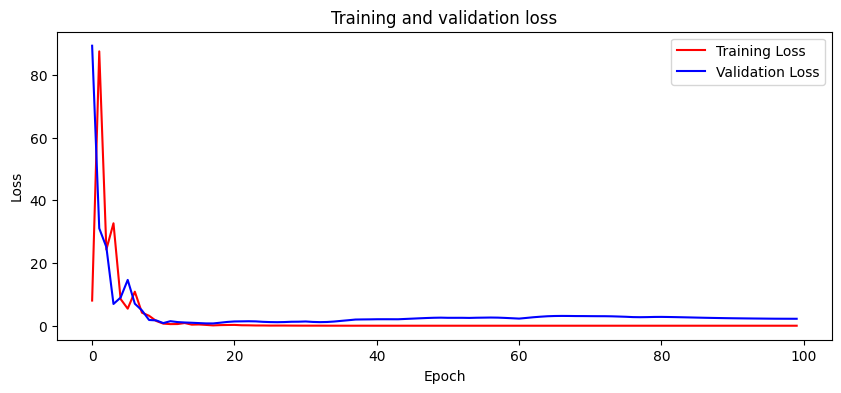

In [ ]:
acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']

epochs=range(len(acc))

fig = plt.figure(figsize=(10,4))
plt.plot(epochs, acc, 'r', label="Training Accuracy")
plt.plot(epochs, val_acc, 'b', label="Validation Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and validation accuracy')
plt.legend(loc='lower right')

fig2 = plt.figure(figsize=(10,4))
plt.plot(epochs, loss, 'r', label="Training Loss")
plt.plot(epochs, val_loss, 'b', label="Validation Loss")
plt.legend(loc='upper right')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and validation loss')
plt.show()

In [ ]:
t_score_train = model1.evaluate(t_X_train, t_y_train, verbose=1)
print('Train accuracy of theta using CNN model:', round(t_score_train[1],4))
t_score_test = model1.evaluate(t_X_test, t_y_test, verbose=1)
print('Test accuracy of theta using CNN model:', round(t_score_test[1],4))

1/1 [==============================] - 0s 81ms/step - loss: 7.3736e-06 - accuracy: 1.0000
Train accuracy of theta using CNN model: 1.0
1/1 [==============================] - 0s 42ms/step - loss: 2.2154 - accuracy: 0.6250
Test accuracy of theta using CNN model: 0.625


In [ ]:
history = model1.fit(b_X_train,
                    b_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(b_X_test, b_y_test),
                    callbacks = [best_model],
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 6.3160 - accuracy: 0.5000
Epoch 1: val_accuracy did not improve from 0.75000
1/1 [==============================] - 0s 306ms/step - loss: 6.3160 - accuracy: 0.5000 - val_loss: 2.7707 - val_accuracy: 0.6250
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 3.9882 - accuracy: 0.5714
Epoch 2: val_accuracy did not improve from 0.75000
1/1 [==============================] - 0s 290ms/step - loss: 3.9882 - accuracy: 0.5714 - val_loss: 2.1041 - val_accuracy: 0.6250
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 2.4631 - accuracy: 0.5714
Epoch 3: val_accuracy did not improve from 0.75000
1/1 [==============================] - 0s 275ms/step - loss: 2.4631 - accuracy: 0.5714 - val_loss: 0.6145 - val_accuracy: 0.7500
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 0.8111 - accuracy: 0.6429
Epoch 4: val_accuracy did not improve from 0.75000
1/1 [==============================] 

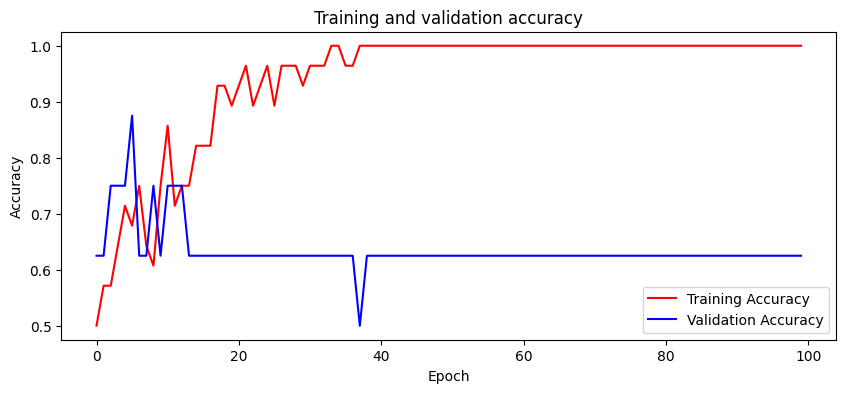

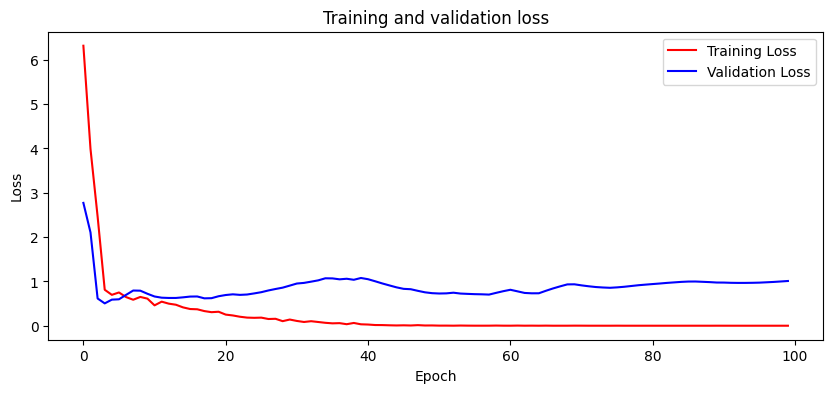

In [ ]:
acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']

epochs=range(len(acc))

fig = plt.figure(figsize=(10,4))
plt.plot(epochs, acc, 'r', label="Training Accuracy")
plt.plot(epochs, val_acc, 'b', label="Validation Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and validation accuracy')
plt.legend(loc='lower right')

fig2 = plt.figure(figsize=(10,4))
plt.plot(epochs, loss, 'r', label="Training Loss")
plt.plot(epochs, val_loss, 'b', label="Validation Loss")
plt.legend(loc='upper right')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and validation loss')
plt.show()

In [ ]:
b_score_train = model1.evaluate(b_X_train, b_y_train, verbose=1)
print('Train accuracy of beta using CNN model:', round(b_score_train[1],4))
b_score_test = model1.evaluate(b_X_test, b_y_test, verbose=1)
print('Test accuracy of beta using CNN model:', round(b_score_test[1],4))

1/1 [==============================] - 0s 86ms/step - loss: 9.1507e-05 - accuracy: 1.0000
Train accuracy of beta using CNN model: 1.0
1/1 [==============================] - 0s 50ms/step - loss: 1.0090 - accuracy: 0.6250
Test accuracy of beta using CNN model: 0.625


# VGG16

In [ ]:
baseModel = VGG16(weights="imagenet", include_top=False,
	input_tensor=Input(shape=(64, 64, 3)))

headModel = baseModel.output
headModel = MaxPooling2D(pool_size=(2, 2))(headModel)
headModel = Flatten(name="flatten")(headModel)
headModel = Dense(256, activation="relu")(headModel)
headModel = Dropout(0.25)(headModel)
headModel = Dense(3, activation="softmax")(headModel)

model = Model(inputs=baseModel.input, outputs=headModel)


for layer in baseModel.layers:
	layer.trainable = False

58889256/58889256 [==============================] - 0s 0us/step


In [ ]:
opt = keras.optimizers.Adam(learning_rate=1e-4)
model.compile(loss="categorical_crossentropy", optimizer=opt,
	metrics=["accuracy"])

In [ ]:
history = model.fit(t_X_train,
                    t_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(t_X_test, t_y_test),
                    callbacks = [best_model]
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 13.1689 - accuracy: 0.3929
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 4s 4s/step - loss: 13.1689 - accuracy: 0.3929 - val_loss: 10.1100 - val_accuracy: 0.2500
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 11.1278 - accuracy: 0.3571
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 11.1278 - accuracy: 0.3571 - val_loss: 8.5526 - val_accuracy: 0.1250
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 8.4498 - accuracy: 0.5357
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 8.4498 - accuracy: 0.5357 - val_loss: 7.4020 - val_accuracy: 0.2500
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 10.7214 - accuracy: 0.4286
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2

In [ ]:
t_score_train = model.evaluate(t_X_train, t_y_train, verbose=1)
print('Train accuracy of theta using VGG16:', round(t_score_train[1],4))
t_score_test = model.evaluate(t_X_test, t_y_test, verbose=1)
print('Test accuracy of theta using VGG16:', round(t_score_test[1],4))

1/1 [==============================] - 1s 1s/step - loss: 0.0153 - accuracy: 1.0000
Train accuracy of theta using VGG16: 1.0
1/1 [==============================] - 0s 359ms/step - loss: 8.0655 - accuracy: 0.3750
Test accuracy of theta using VGG16: 0.375


In [ ]:
history = model.fit(b_X_train,
                    b_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(b_X_test, b_y_test),
                    callbacks = [best_model],
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 6.7036 - accuracy: 0.6071
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 6.7036 - accuracy: 0.6071 - val_loss: 7.5668 - val_accuracy: 0.5000
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 5.3465 - accuracy: 0.6071
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 5.3465 - accuracy: 0.6071 - val_loss: 7.4589 - val_accuracy: 0.5000
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 7.1594 - accuracy: 0.7143
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 7.1594 - accuracy: 0.7143 - val_loss: 7.3062 - val_accuracy: 0.5000
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 5.7807 - accuracy: 0.7143
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/s

In [ ]:
b_score_train = model.evaluate(b_X_train, b_y_train, verbose=1)
print('Train accuracy of beta using VGG16:', round(b_score_train[1],4))
b_score_test = model.evaluate(b_X_test, b_y_test, verbose=1)
print('Test accuracy of beta using VGG16:', round(b_score_test[1],4))

1/1 [==============================] - 1s 1s/step - loss: 0.1910 - accuracy: 0.9643
Train accuracy of beta using VGG16: 0.9643
1/1 [==============================] - 0s 389ms/step - loss: 2.6050 - accuracy: 0.6250
Test accuracy of beta using VGG16: 0.625


In [ ]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0     

# VGG19

In [ ]:
baseModel = VGG19(weights="imagenet", include_top=False,
	input_tensor=Input(shape=(64, 64, 3)))

headModel = baseModel.output
headModel = MaxPooling2D(pool_size=(2, 2))(headModel)
headModel = Flatten(name="flatten")(headModel)
headModel = Dense(256, activation="relu")(headModel)
headModel = Dropout(0.25)(headModel)
headModel = Dense(3, activation="softmax")(headModel)

model2 = Model(inputs=baseModel.input, outputs=headModel)

for layer in baseModel.layers:
	layer.trainable = False

80134624/80134624 [==============================] - 0s 0us/step


In [ ]:
opt = keras.optimizers.Adam(learning_rate=1e-4)
model2.compile(loss="categorical_crossentropy", optimizer=opt,
	metrics=["accuracy"])

In [ ]:
history = model2.fit(t_X_train,
                    t_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(t_X_test, t_y_test),
                    callbacks = [best_model]
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 13.8608 - accuracy: 0.2500
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 3s 3s/step - loss: 13.8608 - accuracy: 0.2500 - val_loss: 8.3416 - val_accuracy: 0.2500
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 15.0549 - accuracy: 0.3214
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 3s 3s/step - loss: 15.0549 - accuracy: 0.3214 - val_loss: 7.7780 - val_accuracy: 0.2500
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 12.5993 - accuracy: 0.3571
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 3s 3s/step - loss: 12.5993 - accuracy: 0.3571 - val_loss: 7.4497 - val_accuracy: 0.3750
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 10.7913 - accuracy: 0.3571
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 

In [ ]:
t_score_train = model2.evaluate(t_X_train, t_y_train, verbose=1)
print('Train accuracy of theta using VGG19:', round(t_score_train[1],4))
t_score_test = model2.evaluate(t_X_test, t_y_test, verbose=1)
print('Test accuracy of theta using VGG19:', round(t_score_test[1],4))

1/1 [==============================] - 2s 2s/step - loss: 0.2206 - accuracy: 0.9643
Train accuracy of theta using VGG19: 0.9643
1/1 [==============================] - 0s 458ms/step - loss: 3.1051 - accuracy: 0.7500
Test accuracy of theta using VGG19: 0.75


In [ ]:
history = model2.fit(b_X_train,
                    b_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(b_X_test, b_y_test),
                    callbacks = [best_model],
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 4.3714 - accuracy: 0.6429
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 4s 4s/step - loss: 4.3714 - accuracy: 0.6429 - val_loss: 2.8960 - val_accuracy: 0.6250
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 2.2524 - accuracy: 0.6786
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 3s 3s/step - loss: 2.2524 - accuracy: 0.6786 - val_loss: 2.9292 - val_accuracy: 0.6250
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 3.2337 - accuracy: 0.6429
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/step - loss: 3.2337 - accuracy: 0.6429 - val_loss: 2.9333 - val_accuracy: 0.6250
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 3.8611 - accuracy: 0.7143
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 2s 2s/s

In [ ]:
b_score_train = model2.evaluate(b_X_train, b_y_train, verbose=1)
print('Train accuracy of beta using VGG19:', round(b_score_train[1],4))
b_score_test = model2.evaluate(b_X_test, b_y_test, verbose=1)
print('Test accuracy of beta using VGG19:', round(b_score_test[1],4))

1/1 [==============================] - 2s 2s/step - loss: 0.1175 - accuracy: 0.9643
Train accuracy of beta using VGG19: 0.9643
1/1 [==============================] - 1s 888ms/step - loss: 3.4563 - accuracy: 0.6250
Test accuracy of beta using VGG19: 0.625


# Xception

In [ ]:
baseModel = Xception(weights="imagenet", include_top=False,
	input_tensor=Input(shape=(64, 64, 3)))

headModel = baseModel.output
headModel = MaxPooling2D(pool_size=(2, 2))(headModel)
headModel = Flatten(name="flatten")(headModel)
headModel = Dense(256, activation="relu")(headModel)
headModel = Dropout(0.25)(headModel)
headModel = Dense(3, activation="softmax")(headModel)

model3 = Model(inputs=baseModel.input, outputs=headModel)


for layer in baseModel.layers:
	layer.trainable = False

83683744/83683744 [==============================] - 1s 0us/step


In [ ]:
opt = keras.optimizers.Adam(learning_rate=1e-4)
model3.compile(loss="categorical_crossentropy", optimizer=opt,
	metrics=["accuracy"])

In [ ]:
history = model3.fit(t_X_train,
                    t_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(t_X_test, t_y_test),
                    callbacks = [best_model]
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 12.4844 - accuracy: 0.3929
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 12s 12s/step - loss: 12.4844 - accuracy: 0.3929 - val_loss: 4.4204 - val_accuracy: 0.3750
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 8.4665 - accuracy: 0.4643
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 1s/step - loss: 8.4665 - accuracy: 0.4643 - val_loss: 2.1964 - val_accuracy: 0.6250
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 4.4873 - accuracy: 0.4286
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 1s/step - loss: 4.4873 - accuracy: 0.4286 - val_loss: 3.8779 - val_accuracy: 0.6250
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 9.9954 - accuracy: 0.3214
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 

In [ ]:
t_score_train = model3.evaluate(t_X_train, t_y_train, verbose=1)
print('Train accuracy of theta using Xception:', round(t_score_train[1],4))
t_score_test = model3.evaluate(t_X_test, t_y_test, verbose=1)
print('Test accuracy of theta using Xception:', round(t_score_test[1],4))

1/1 [==============================] - 1s 789ms/step - loss: 0.0718 - accuracy: 0.9643
Train accuracy of theta using Xception: 0.9643
1/1 [==============================] - 0s 294ms/step - loss: 6.1986 - accuracy: 0.5000
Test accuracy of theta using Xception: 0.5


In [ ]:
history = model3.fit(b_X_train,
                    b_y_train,
                    epochs=100,
                    verbose=1,
                    validation_data=(b_X_test, b_y_test),
                    callbacks = [best_model],
                    )

Epoch 1/100
1/1 [==============================] - ETA: 0s - loss: 6.3040 - accuracy: 0.5714
Epoch 1: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 1s/step - loss: 6.3040 - accuracy: 0.5714 - val_loss: 3.3717 - val_accuracy: 0.7500
Epoch 2/100
1/1 [==============================] - ETA: 0s - loss: 4.1284 - accuracy: 0.5714
Epoch 2: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 676ms/step - loss: 4.1284 - accuracy: 0.5714 - val_loss: 4.0607 - val_accuracy: 0.6250
Epoch 3/100
1/1 [==============================] - ETA: 0s - loss: 5.6527 - accuracy: 0.6429
Epoch 3: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1s 605ms/step - loss: 5.6527 - accuracy: 0.6429 - val_loss: 5.2118 - val_accuracy: 0.3750
Epoch 4/100
1/1 [==============================] - ETA: 0s - loss: 4.5588 - accuracy: 0.5714
Epoch 4: val_accuracy did not improve from 0.87500
1/1 [==============================] - 1

In [ ]:
b_score_train = model3.evaluate(b_X_train, b_y_train, verbose=1)
print('Train accuracy of beta using Xception:', round(b_score_train[1],4))
b_score_test = model3.evaluate(b_X_test, b_y_test, verbose=1)
print('Test accuracy of beta using Xception:', round(b_score_test[1],4))

1/1 [==============================] - 0s 460ms/step - loss: 0.0168 - accuracy: 1.0000
Train accuracy of beta using Xception: 1.0
1/1 [==============================] - 0s 166ms/step - loss: 1.8514 - accuracy: 0.6250
Test accuracy of beta using Xception: 0.625
